# Q-Avoid: quantum amplitude estimation for satellite collision risk

When two objects are predicted to pass close to each other, the operator gets a Conjunction Data Message (CDM) and has to decide whether to spend fuel on an avoidance maneuver. That decision hinges on one number: the **probability of collision, Pc**. A common rule of thumb is to maneuver if Pc ≥ 1e-4.

Pc is a rare-event probability. Monte Carlo, the general-purpose tool when the model gets non-linear or non-Gaussian, is very inefficient for rare events: the relative error goes as $\sqrt{(1-P_c)/(P_c N)}$, so a 1e-4 event needs around a million samples to reach 10% accuracy.

**This notebook:**
1. Takes real conjunctions from ESA's Kelvins Collision Avoidance dataset (anonymised CDMs, 2015–2019).
2. Builds a classical baseline: a reference integral (ground truth) and Monte Carlo.
3. Encodes the same problem in a Qiskit circuit and estimates Pc with **maximum-likelihood amplitude estimation (MLAE)**.
4. Compares the two **at equal cost**, counting one oracle call (one evaluation of the uncertainty model) as one unit for both methods.

Only the estimation step is quantum. Data handling, geometry, and the final decision stay classical.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from pathlib import Path

from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler

from qavoid.encounter import load_kelvins, encounter_from_row
from qavoid.classical import pc_reference, pc_monte_carlo, pc_monte_carlo_fast
from qavoid.quantum import (encode_grid, build_state_preparation, build_grover, amplified_circuit,
                            mlae_schedule, oracle_queries, mlae_circuits, run_mlae_qiskit, run_mlae_ideal)

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C_MC, C_QAE = "#d1495b", "#2e86ab"

HBR = 10.0              # combined hard-body radius in metres (not in the dataset, see below)
THRESHOLD = 1e-4        # maneuver if Pc >= this
rng = np.random.default_rng(2026)

## 1. Data: from CDMs to the encounter plane

We keep the **last CDM** before closest approach for every event, which is the one a maneuver decision is based on. We also drop events ESA rated below 1e-6, since nobody would maneuver for those.

Each CDM has the relative position and velocity in the target's RTN frame, plus position uncertainties for both objects. Under the standard short-term-encounter assumption, we project everything onto the plane perpendicular to the relative velocity. Pc is then the mass of a 2D Gaussian inside a disk of radius R around the origin.

In [2]:
events = load_kelvins("data/train_data.csv", min_log_risk=-6.0)
encounters = [encounter_from_row(row, hbr=HBR) for _, row in events.iterrows()]
pc_true = np.array([pc_reference(e) for e in encounters])
esa_log = events["risk"].to_numpy()

print(f"{len(events)} events with ESA risk > 1e-6")
log_ours = np.log10(np.maximum(pc_true, 1e-30))
diff = log_ours - esa_log
print(f"median log10(ours / ESA) = {np.median(diff):+.2f},  within 1 order of magnitude: {np.mean(np.abs(diff) < 1):.0%}")

365 events with ESA risk > 1e-6
median log10(ours / ESA) = +0.05,  within 1 order of magnitude: 63%


**Sanity check against ESA's operational numbers.** The dataset doesn't include the hard-body radius. Also, because the data is anonymised, we have to treat the chaser covariance as if it were in the target's frame. With R = 10 m our median Pc agrees with ESA's to within a few hundredths of a decade, which is good enough to treat these as realistic encounter geometries. From here on, **our reference integral is the ground truth** that both estimators are scored against.

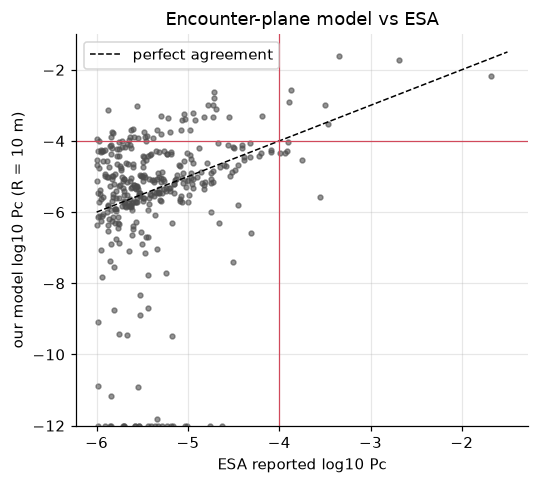

In [3]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(esa_log, np.clip(log_ours, -12, None), s=10, alpha=0.6, color="0.3")
ax.plot([-6, -1.5], [-6, -1.5], "k--", lw=1, label="perfect agreement")
ax.axhline(np.log10(THRESHOLD), color=C_MC, lw=0.8); ax.axvline(np.log10(THRESHOLD), color=C_MC, lw=0.8)
ax.set(xlabel="ESA reported log10 Pc", ylabel="our model log10 Pc (R = 10 m)", ylim=(-12, -1),
       title="Encounter-plane model vs ESA")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "model_vs_esa.png")

## 2. One showcase event

We pick a real event whose Pc is just above the maneuver threshold, which is exactly the case where getting the estimate right matters.

In [4]:
i_show = int(np.argmin(np.abs(np.log10(pc_true + 1e-300) - np.log10(3e-4))))
enc = encounters[i_show]
PC = pc_true[i_show]
print(f"event {enc.event_id}: miss distance {enc.miss_distance:.0f} m, "
      f"sigma = {enc.sigma.round(1)} m, Pc = {PC:.3e} (ESA: {10**enc.esa_log_risk:.2e})")

event 12555: miss distance 546 m, sigma = [  81.3 1747.8] m, Pc = 3.007e-04 (ESA: 3.38e-04)


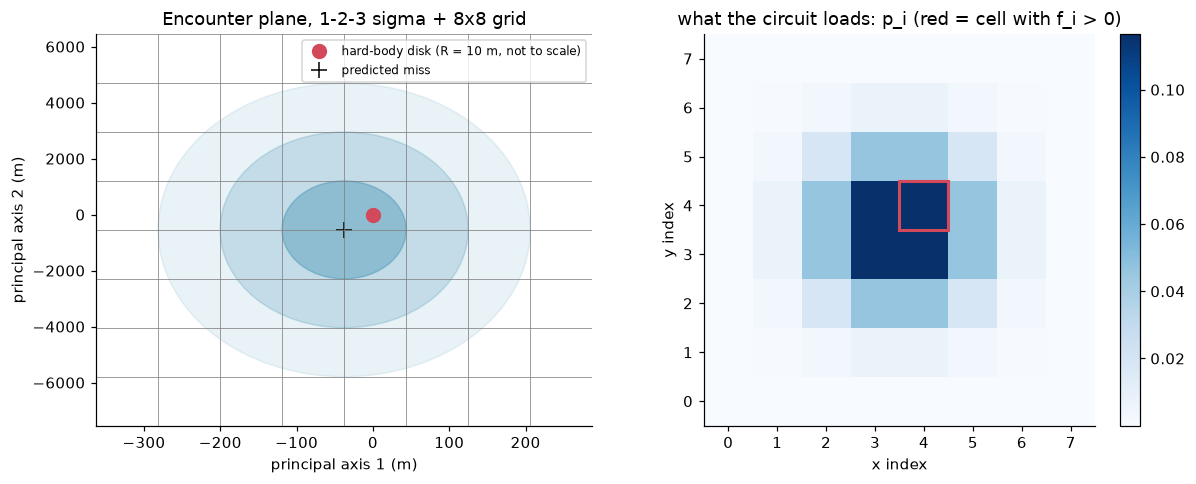

In [5]:
grid = encode_grid(enc, n_bits=3)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
for k, a in [(1, 0.35), (2, 0.2), (3, 0.1)]:
    ax.add_patch(Ellipse(enc.mean, 2 * k * enc.sigma[0], 2 * k * enc.sigma[1], color=C_QAE, alpha=a))
# axes are very unequal, so mark the 10 m disk with a symbol rather than to scale
ax.plot(0, 0, "o", color=C_MC, ms=9, label=f"hard-body disk (R = {enc.hbr:.0f} m, not to scale)")
ax.plot(*enc.mean, "k+", ms=10, label="predicted miss")
for e in grid.edges[0]: ax.axvline(e, color="0.5", lw=0.5)
for e in grid.edges[1]: ax.axhline(e, color="0.5", lw=0.5)
ax.set(xlabel="principal axis 1 (m)", ylabel="principal axis 2 (m)", title="Encounter plane, 1-2-3 sigma + 8x8 grid")
ax.set_xlim(grid.edges[0][[0, -1]]); ax.set_ylim(grid.edges[1][[0, -1]]); ax.grid(False)
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
im = ax.imshow(np.outer(grid.px, grid.py).T, origin="lower", cmap="Blues")
hit_cells = np.argwhere(grid.f > 0)
for ix, iy in hit_cells:
    ax.add_patch(plt.Rectangle((ix - .5, iy - .5), 1, 1, fill=False, ec=C_MC, lw=2))
ax.set(title="what the circuit loads: p_i (red = cell with f_i > 0)", xlabel="x index", ylabel="y index")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(FIG / "encounter_plane.png")

## 3. Classical baseline: Monte Carlo

Sample relative positions from the Gaussian and count how many land inside the disk.

For the big sweeps later we use the fact that the hit count is exactly Binomial(N, Pc), so we draw the count directly instead of a million points per trial. The cell below checks that the shortcut and the real sampler give the same error.

In [6]:
N = 100_000
real = np.array([pc_monte_carlo(enc, N, rng) for _ in range(30)])
fast = pc_monte_carlo_fast(PC, N, rng, size=30)
print(f"N = {N:,}: real MC  mean {real.mean():.2e}, rel. std {real.std() / PC:.2f}")
print(f"           binomial mean {fast.mean():.2e}, rel. std {fast.std() / PC:.2f}")
print(f"           theory   rel. std {np.sqrt((1 - PC) / (PC * N)):.2f}")

N = 100,000: real MC  mean 2.99e-04, rel. std 0.19
           binomial mean 3.01e-04, rel. std 0.17
           theory   rel. std 0.18


## 4. The quantum subroutine

**State preparation A** (7 qubits: 3 for x, 3 for y, 1 "hit" qubit):

$$A|0\rangle = \sum_i \sqrt{p_i}\,|i\rangle\big(\sqrt{1-f_i}\,|0\rangle + \sqrt{f_i}\,|1\rangle\big)$$

- $p_i$ is the probability that the relative position falls in grid cell $i$. Because the Gaussian is axis-aligned in principal axes, the x and y registers are loaded independently.
- $f_i$ is the probability of a hit *given* the object is in cell $i$, written onto the hit qubit with a uniformly-controlled RY.

So the probability of measuring the hit qubit as 1 is $a = \sum_i p_i f_i = P_c$. Because $f_i$ is the exact conditional probability, the grid does not bias the answer.

**Amplification.** The Grover operator $Q = A S_0 A^\dagger S_\chi$ rotates the state by $2\theta$ each time, where $a=\sin^2\theta$. After $k$ applications, $P(\text{hit}) = \sin^2((2k+1)\theta)$. MLAE runs a few values of $k$ and fits $\theta$, with no phase-estimation register needed.

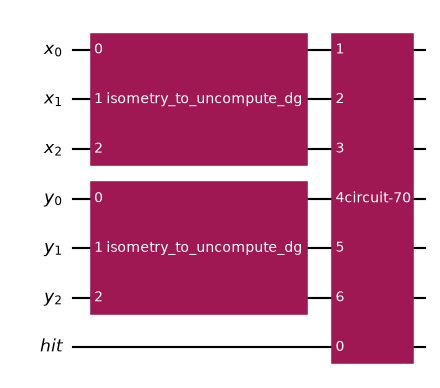

In [7]:
A = build_state_preparation(grid)
A.decompose().draw("mpl", fold=-1, scale=0.7)

P(hit qubit = 1) from statevector: 3.007282e-04
reference integral Pc:             3.007282e-04


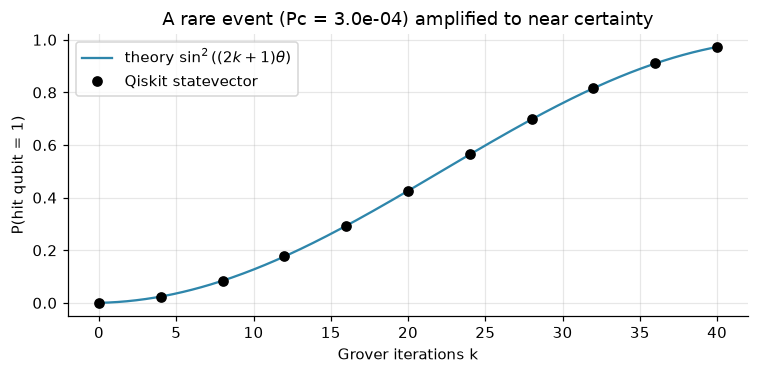

In [8]:
p_hit = Statevector(A).probabilities([A.num_qubits - 1])[1]
print(f"P(hit qubit = 1) from statevector: {p_hit * grid.box_mass:.6e}")
print(f"reference integral Pc:             {PC:.6e}")

# Check Grover amplification against the theory curve
G = build_grover(A)
theta = np.arcsin(np.sqrt(grid.amplitude))
ks = np.arange(0, 41, 4)
measured = [Statevector(amplified_circuit(A, G, k).remove_final_measurements(inplace=False))
            .probabilities([A.num_qubits - 1])[1] for k in ks]

kk = np.linspace(0, 40, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(kk, np.sin((2 * kk + 1) * theta) ** 2, color=C_QAE, label=r"theory $\sin^2((2k+1)\theta)$")
ax.plot(ks, measured, "o", color="k", label="Qiskit statevector")
ax.set(xlabel="Grover iterations k", ylabel="P(hit qubit = 1)",
       title=f"A rare event (Pc = {PC:.1e}) amplified to near certainty")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "amplification.png")

### Full MLAE run on the Qiskit sampler

Schedule $k = 0, 1, 2, 4, \dots, 32$ with 100 shots per circuit. Each shot of $AQ^k$ calls the model $2k+1$ times, which is the number we charge against the quantum method.

For the large sweeps we again use a fast path: on an ideal device the hit qubit after $AQ^k$ is exactly Bernoulli($\sin^2((2k+1)\theta)$), so we draw binomial counts directly. The cell below confirms this matches the real Qiskit circuits.

In [9]:
SHOTS = 100
schedule = mlae_schedule(7)
circuits = mlae_circuits(A, schedule, seed=7)
print("schedule k:", schedule, "| oracle queries per estimate:", oracle_queries(schedule, SHOTS))
print("deepest circuit:", circuits[-1].count_ops().get("cx", 0), "CNOTs")

# a Generator (not an int) so each run gets fresh shots
sampler = StatevectorSampler(seed=np.random.default_rng(11))
qiskit_runs = np.array([run_mlae_qiskit(circuits, schedule, SHOTS, sampler)[0] for _ in range(40)]) * grid.box_mass
ideal_runs = np.array([run_mlae_ideal(grid.amplitude, schedule, SHOTS, rng)[0] for _ in range(200)]) * grid.box_mass

for name, r in [("Qiskit sampler", qiskit_runs), ("ideal fast path", ideal_runs)]:
    print(f"{name:16s} mean {r.mean():.3e}   rel. RMSE {np.sqrt(np.mean((r - PC) ** 2)) / PC:.3f}")

schedule k: [0, 1, 2, 4, 8, 16, 32] | oracle queries per estimate: 13300
deepest circuit: 8648 CNOTs


Qiskit sampler   mean 2.984e-04   rel. RMSE 0.083
ideal fast path  mean 2.993e-04   rel. RMSE 0.077


## 5. The core result: error vs. cost

Both methods get the same budget of oracle calls. We repeat each budget 300 times and measure the relative RMSE.

In [10]:
def sweep(a, box_mass, pc, powers=range(1, 12), shots=SHOTS, reps=300):
    rows = []
    for m in powers:
        sch = mlae_schedule(m)
        n = oracle_queries(sch, shots)
        q = np.array([run_mlae_ideal(a, sch, shots, rng)[0] for _ in range(reps)]) * box_mass
        c = pc_monte_carlo_fast(pc, n, rng, size=reps)
        rows.append(dict(queries=n, qae=np.sqrt(np.mean((q - pc) ** 2)) / pc,
                         mc=np.sqrt(np.mean((c - pc) ** 2)) / pc))
    return pd.DataFrame(rows)

res = sweep(grid.amplitude, grid.box_mass, PC)
res.style.format({"queries": "{:,}", "qae": "{:.3f}", "mc": "{:.3f}"})

,queries,qae,mc
0,100,5.024,5.970
1,400,1.867,3.023
2,900,0.966,2.012
3,"1,800",0.553,1.285
4,"3,500",0.298,0.938
5,"6,800",0.129,0.690
6,"13,300",0.075,0.515
7,"26,200",0.039,0.362
8,"51,900",0.021,0.249
9,"103,200",0.010,0.184


At 205,700 calls: MLAE 0.5% error vs Monte Carlo 12.1%.
Monte Carlo would need ~1.2e+08 calls to match.


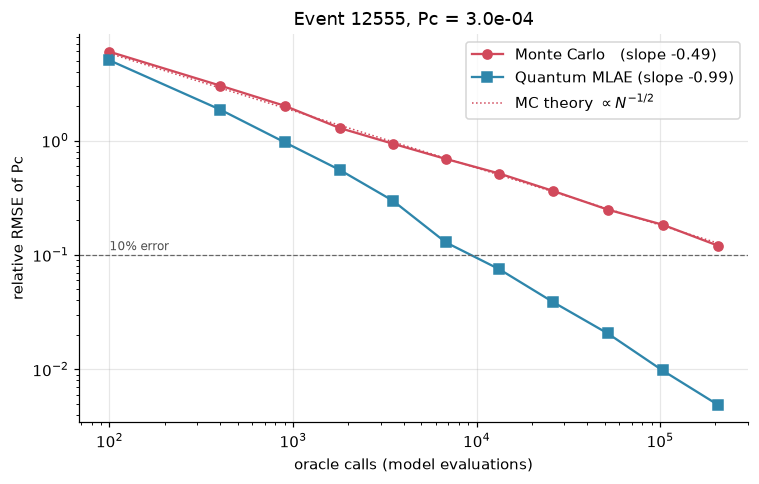

In [11]:
fit = lambda df, col: np.polyfit(np.log10(df.queries[3:]), np.log10(df[col][3:]), 1)[0]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(res.queries, res.mc, "o-", color=C_MC, label=f"Monte Carlo   (slope {fit(res, 'mc'):.2f})")
ax.loglog(res.queries, res.qae, "s-", color=C_QAE, label=f"Quantum MLAE (slope {fit(res, 'qae'):.2f})")
n = res.queries.to_numpy()
ax.loglog(n, np.sqrt((1 - PC) / (PC * n)), ":", color=C_MC, lw=1, label=r"MC theory $\propto N^{-1/2}$")
ax.axhline(0.1, color="0.4", lw=0.8, ls="--"); ax.text(n[0], 0.11, "10% error", fontsize=8, color="0.3")
ax.set(xlabel="oracle calls (model evaluations)", ylabel="relative RMSE of Pc",
       title=f"Event {enc.event_id}, Pc = {PC:.1e}")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "error_vs_queries.png")

i = res.index[-1]
print(f"At {res.queries[i]:,} calls: MLAE {res.qae[i]:.1%} error vs Monte Carlo {res.mc[i]:.1%}.")
print(f"Monte Carlo would need ~{(res.mc[i] / res.qae[i]) ** 2 * res.queries[i]:.1e} calls to match.")

## 6. Why this matters more for rarer events

To reach a 10% relative error, Monte Carlo needs $\approx 100/P_c$ samples, while amplitude estimation needs $\approx \mathcal{O}(1/\sqrt{P_c})$ calls. So the rarer the event, the bigger the gap. We measure the cost directly for amplitudes from 1e-2 down to 1e-6.

,pc,mc,qae,speedup
0,1e-02,"9,900","1,800",5x
1,3e-03,"31,523","3,500",9x
2,1e-03,"99,900","6,800",15x
3,3e-04,"316,128","13,300",24x
4,1e-04,"999,900","26,200",38x
5,3e-05,"3,162,178","51,900",61x
6,1e-05,"9,999,900","103,200",97x
7,3e-06,"31,622,677","103,200",306x
8,1e-06,"99,999,900","205,700",486x


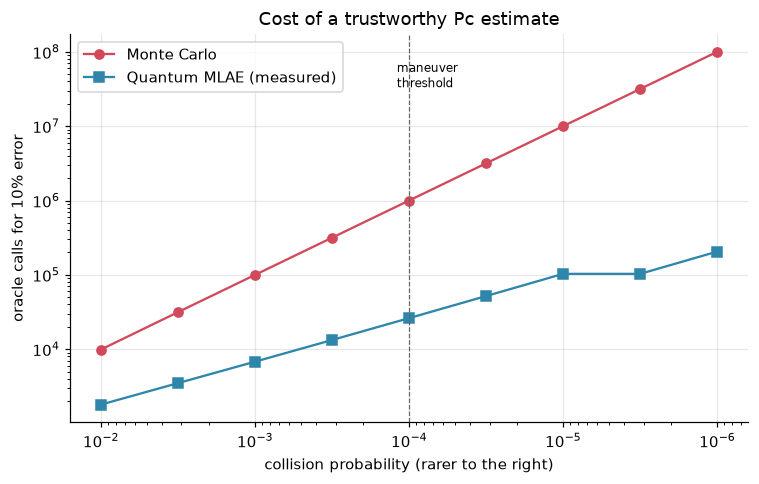

In [12]:
def calls_for_target(a, target=0.1, shots=SHOTS, reps=200):
    for m in range(1, 16):
        sch = mlae_schedule(m)
        q = np.array([run_mlae_ideal(a, sch, shots, rng)[0] for _ in range(reps)])
        if np.sqrt(np.mean((q - a) ** 2)) / a < target:
            return oracle_queries(sch, shots)
    return np.nan

pcs = np.logspace(-2, -6, 9)
cost = pd.DataFrame({"pc": pcs,
                     "mc": (1 - pcs) / (pcs * 0.1 ** 2),
                     "qae": [calls_for_target(a) for a in pcs]})
cost["speedup"] = cost.mc / cost.qae

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(cost.pc, cost.mc, "o-", color=C_MC, label="Monte Carlo")
ax.loglog(cost.pc, cost.qae, "s-", color=C_QAE, label="Quantum MLAE (measured)")
ax.axvline(THRESHOLD, color="0.4", ls="--", lw=0.8); ax.text(THRESHOLD * 1.2, cost.mc.max() / 3, "maneuver\nthreshold", fontsize=8)
ax.invert_xaxis()
ax.set(xlabel="collision probability (rarer to the right)", ylabel="oracle calls for 10% error",
       title="Cost of a trustworthy Pc estimate")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "cost_vs_rarity.png")
cost.style.format({"pc": "{:.0e}", "mc": "{:,.0f}", "qae": "{:,.0f}", "speedup": "{:.0f}x"})

## 7. Does it change decisions?

This is the operational question. We give every event with Pc between 1e-6 and 1e-2 a fixed budget of oracle calls, have each method estimate Pc 200 times, and compare its maneuver call against the true one.

In [13]:
BUDGET_POWERS = 6
sch = mlae_schedule(BUDGET_POWERS)
budget = oracle_queries(sch, SHOTS)
mask = (pc_true > 1e-6) & (pc_true < 1e-2)
print(f"{mask.sum()} events, {budget:,} oracle calls per estimate")

rows = []
for e, pc in zip(np.array(encounters, dtype=object)[mask], pc_true[mask]):
    g = encode_grid(e, n_bits=3)
    q = np.array([run_mlae_ideal(g.amplitude, sch, SHOTS, rng)[0] for _ in range(200)]) * g.box_mass
    c = pc_monte_carlo_fast(pc, budget, rng, size=200)
    truth = pc >= THRESHOLD
    rows.append(dict(event=e.event_id, pc=pc, maneuver=truth,
                     qae_correct=np.mean((q >= THRESHOLD) == truth),
                     mc_correct=np.mean((c >= THRESHOLD) == truth)))
dec = pd.DataFrame(rows)

print(f"\nCorrect maneuver decisions:  Monte Carlo {dec.mc_correct.mean():.1%}   Quantum MLAE {dec.qae_correct.mean():.1%}")
near = dec[(dec.pc > THRESHOLD / 5) & (dec.pc < THRESHOLD * 5)]
print(f"Hard cases (Pc within 5x of threshold, n={len(near)}):  MC {near.mc_correct.mean():.1%}   MLAE {near.qae_correct.mean():.1%}")

286 events, 6,800 oracle calls per estimate



Correct maneuver decisions:  Monte Carlo 87.6%   Quantum MLAE 97.7%
Hard cases (Pc within 5x of threshold, n=103):  MC 72.3%   MLAE 93.7%


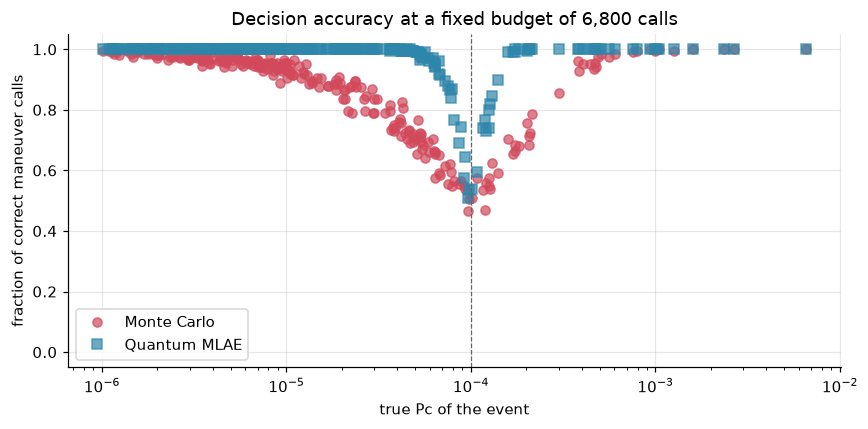

In [14]:
d = dec.sort_values("pc")
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(d.pc, d.mc_correct, "o", color=C_MC, alpha=0.7, label="Monte Carlo")
ax.semilogx(d.pc, d.qae_correct, "s", color=C_QAE, alpha=0.7, label="Quantum MLAE")
ax.axvline(THRESHOLD, color="0.4", ls="--", lw=0.8)
ax.set(xlabel="true Pc of the event", ylabel="fraction of correct maneuver calls",
       title=f"Decision accuracy at a fixed budget of {budget:,} calls", ylim=(-0.05, 1.05))
ax.legend(loc="lower left"); fig.tight_layout(); fig.savefig(FIG / "decision_accuracy.png")

## 8. What this does and doesn't show

**Shown, on real conjunction geometries:**
- At equal cost, amplitude estimation error falls as about $N^{-1}$ while Monte Carlo falls as $N^{-1/2}$.
- The advantage grows as events get rarer, and collision avoidance is entirely about rare events.
- At a fixed budget this turns into more correct maneuver decisions near the threshold.

**Honest limits:**
- **Cost model.** We count oracle calls, not wall-clock time. The simulator is not faster than a laptop running Monte Carlo, and the claim is about query complexity.
- **Oracle construction.** Here $p_i$ and $f_i$ are computed classically and loaded. In the 2D Gaussian case, that is as hard as the problem itself. The case that matters is a high-fidelity model (non-linear relative motion, non-Gaussian uncertainty, many orbital elements) where only sampling works. There, $A$ would be a reversible circuit that propagates the uncertainty, and building it efficiently is an open engineering problem.
- **Hardware.** Ideal simulation only. The deepest circuit in section 4 ($k=32$) already has about 8,600 CNOTs after transpiling, which is beyond today's noisy devices without error mitigation or error correction. MLAE's short, shallow-first schedule is the friendliest variant, but noise would cap the useful $k$.
- **Model.** Chaser covariance frame and hard-body radius are approximated, as described in section 1.

**Next steps:** add a noise model to find the largest useful $k$, use power-law MLAE schedules tuned to noise, and build $A$ from a sampled orbital propagator instead of a closed-form Gaussian.